In [1]:
# Importação de Bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from pathlib import Path
import shutil
import numpy as np

/home/erick/Projetos/tech-challenger-2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Variáveis de Configuração
DATASET_NAME = "imakash3011/online-shoppers-purchasing-intention-dataset"
OUTPUT_DIR = Path("data")
FILENAME = "online_shoppers_intention.csv"


# Download do Dataset
dataset_path = Path(kagglehub.dataset_download(DATASET_NAME, force_download=True))
source_file = dataset_path / FILENAME

if not source_file.exists():
    raise FileNotFoundError(f"Arquivo {FILENAME} não encontrado no dataset.")

output_file = Path(OUTPUT_DIR)
output_file.mkdir(parents=True, exist_ok=True)
shutil.copy(source_file, output_file)


100%|██████████| 252k/252k [00:00<00:00, 517kB/s]

Extracting files...


'data/online_shoppers_intention.csv'

In [3]:
# Leitura do Dataset
df = pd.read_csv("data/online_shoppers_intention.csv")
df.head()


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
print("\n============================== Descrição estatística do dataset ==============================\n")
print(df.describe())

print("\n============================== Informações sobre o dataset ==============================\n")
print(df.info())



============================== Descrição estatística do dataset ==============================

       Administrative  Administrative_Duration  Informational  \
count    12330.000000             12330.000000   12330.000000   
mean         2.315166                80.818611       0.503569   
std          3.321784               176.779107       1.270156   
min          0.000000                 0.000000       0.000000   
25%          0.000000                 0.000000       0.000000   
50%          1.000000                 7.500000       0.000000   
75%          4.000000                93.256250       0.000000   
max         27.000000              3398.750000      24.000000   

       Informational_Duration  ProductRelated  ProductRelated_Duration  \
count            12330.000000    12330.000000             12330.000000   
mean                34.472398       31.731468              1194.746220   
std                140.749294       44.475503              1913.669288   
min                  

In [5]:
# Verificação de valores nulos
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [6]:
print(f"Shape do DataFrame: {df.shape}")

Shape do DataFrame: (12330, 18)


In [7]:
df[df.duplicated()]



,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,False,False
418,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,True,False
456,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,4,1,Returning_Visitor,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11934,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,2,New_Visitor,False,False
11938,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,4,1,Returning_Visitor,True,False
12159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,1,1,3,Returning_Visitor,False,False
12180,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Dec,1,13,9,20,Returning_Visitor,False,False


In [8]:
# Remoção de duplicatas
df = df.drop_duplicates()

print(f"Shape do DataFrame após remoção de duplicatas: {df.shape}")

Shape do DataFrame após remoção de duplicatas: (12205, 18)


In [9]:
num_cols = [col for col in df.columns if df[col].dtype in ['int64', 'float64']]
cat_cols = [col for col in df.columns if df[col].dtype == 'str']
bool_cols = [col for col in df.columns if df[col].dtype == 'bool']

print("\n============================== Colunas Numéricas ==============================\n")
for num in num_cols:
    print(num)

print("\n============================== Colunas Categóricas ==============================\n")
for cat in cat_cols:
    print(cat)

print("\n============================== Colunas Booleanas ==============================\n")
for boolean in bool_cols:
    print(boolean)



============================== Colunas Numéricas ==============================

Administrative
Administrative_Duration
Informational
Informational_Duration
ProductRelated
ProductRelated_Duration
BounceRates
ExitRates
PageValues
SpecialDay
OperatingSystems
Browser
Region
TrafficType

============================== Colunas Categóricas ==============================

Month
VisitorType

============================== Colunas Booleanas ==============================

Weekend
Revenue


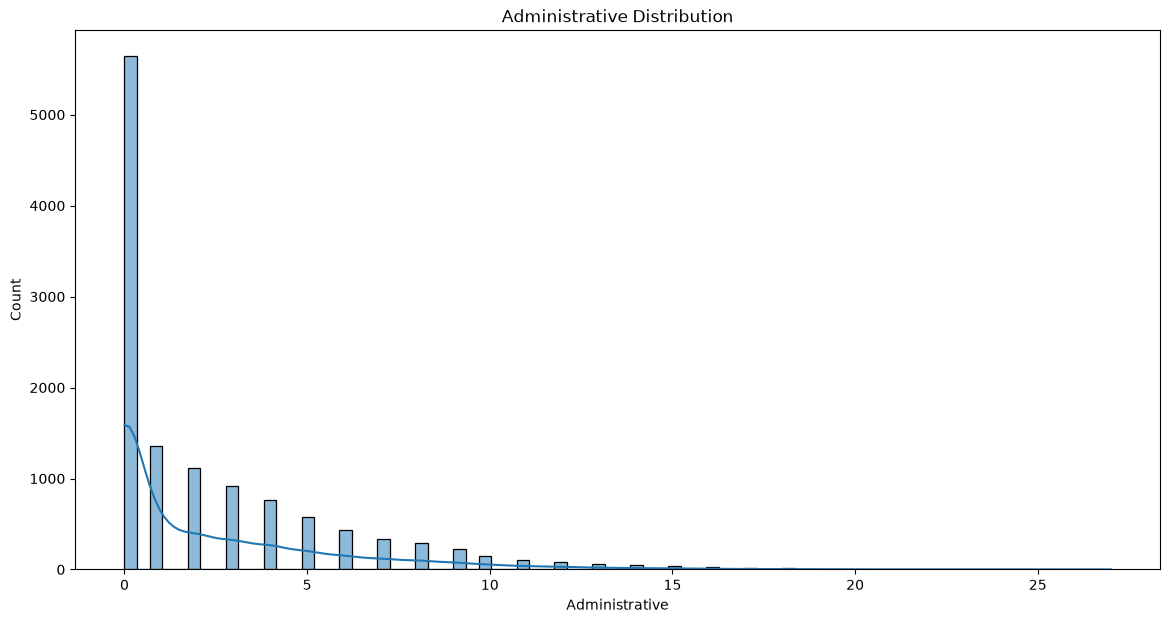

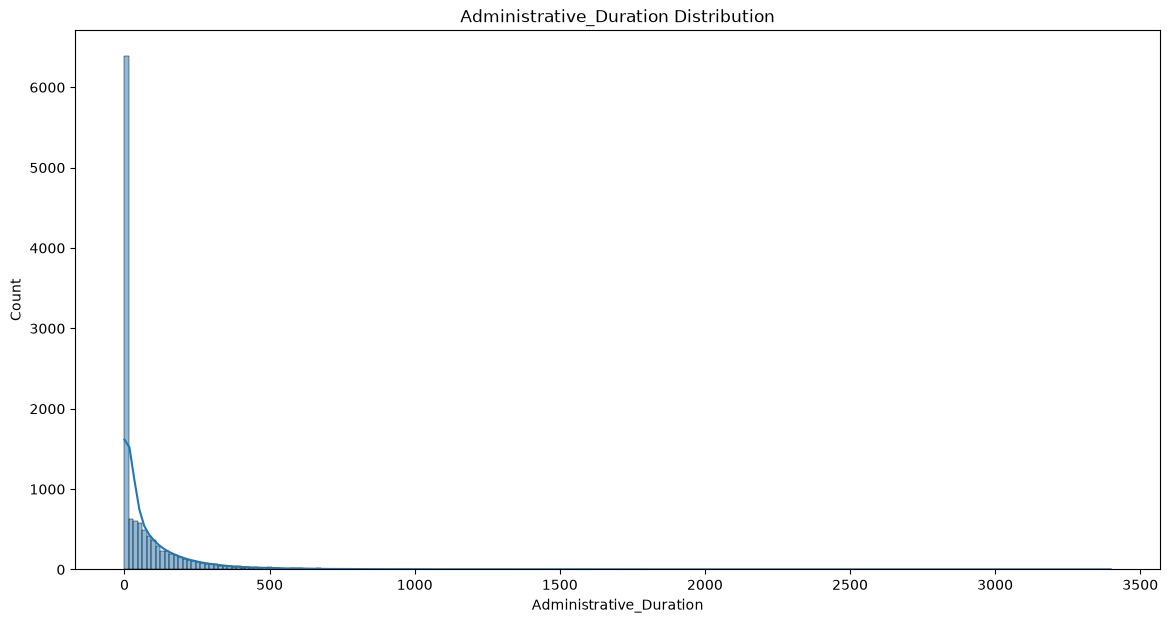

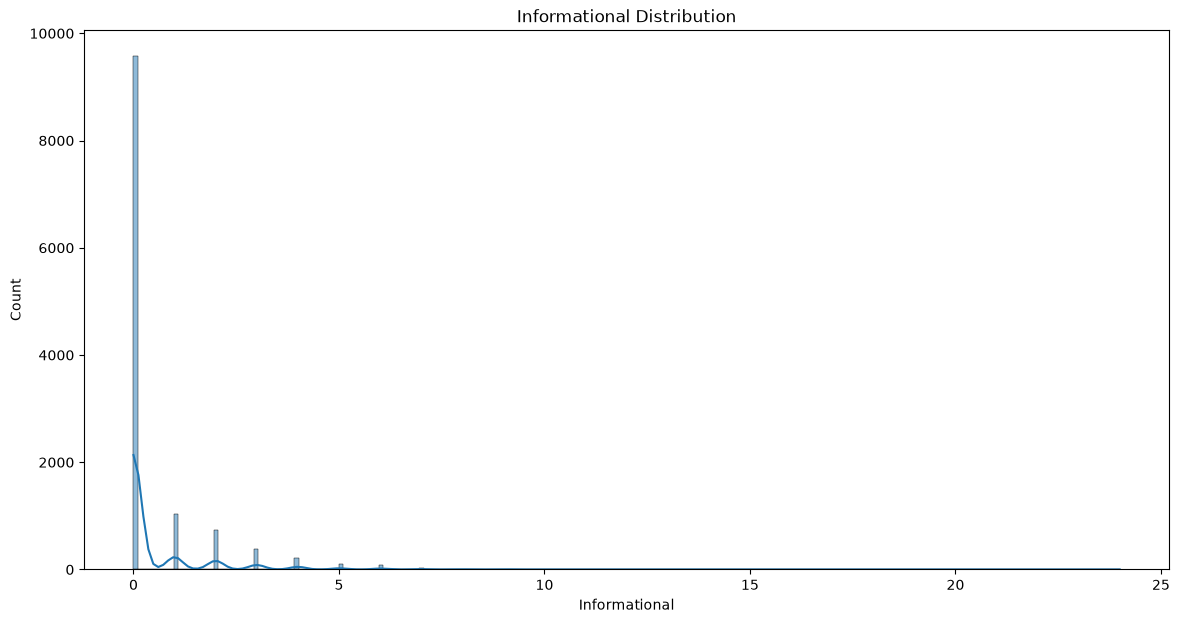

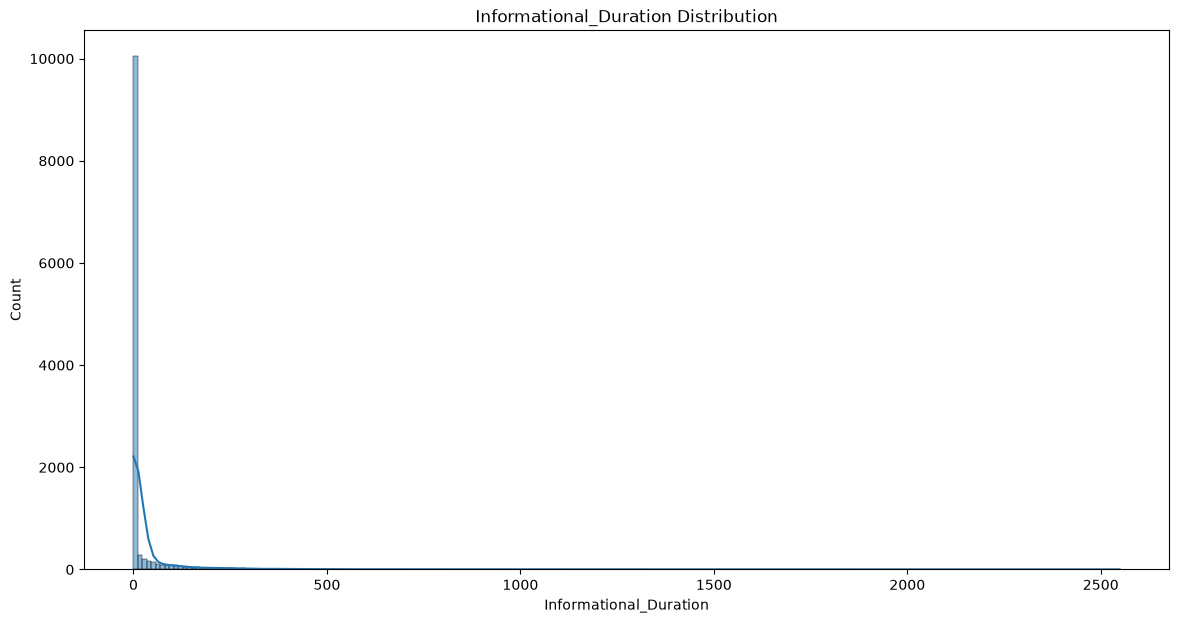

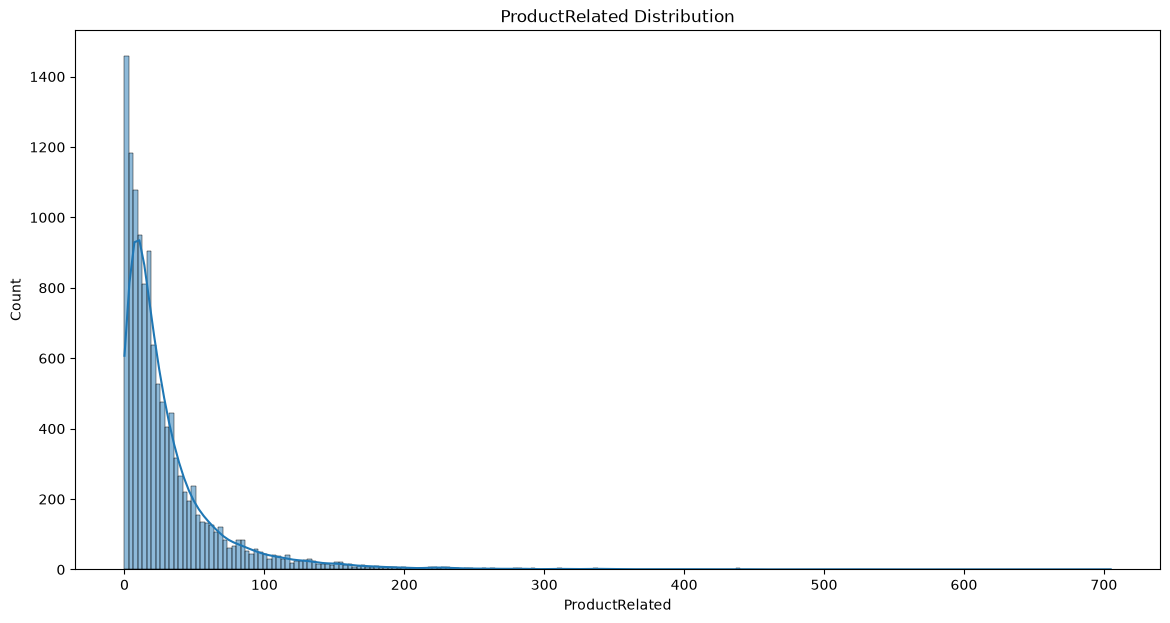

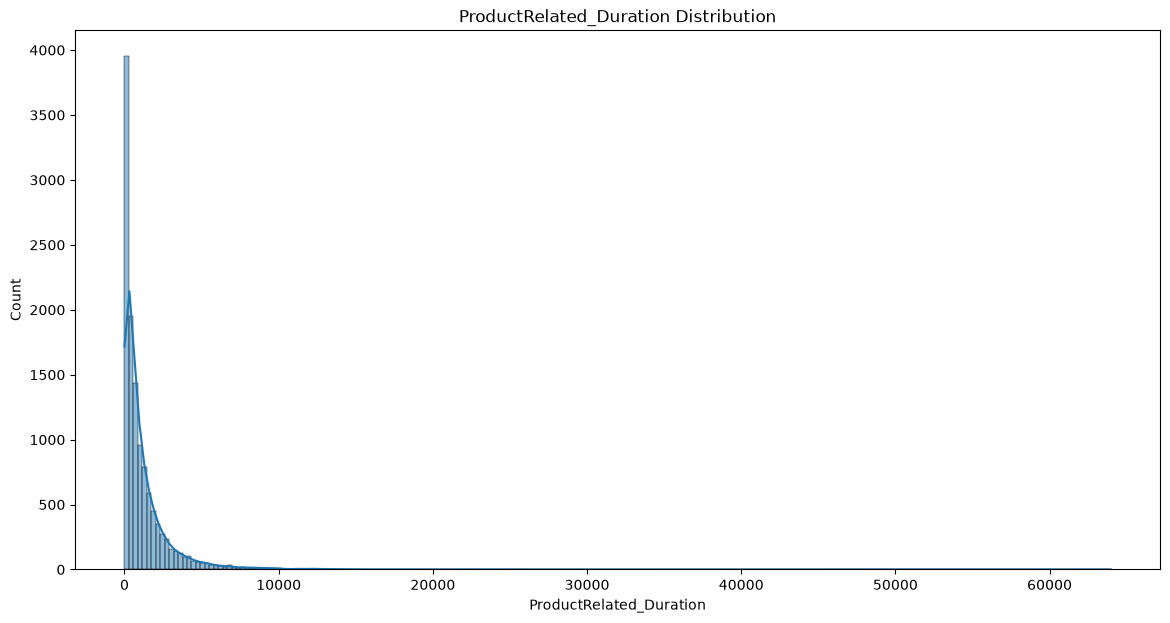

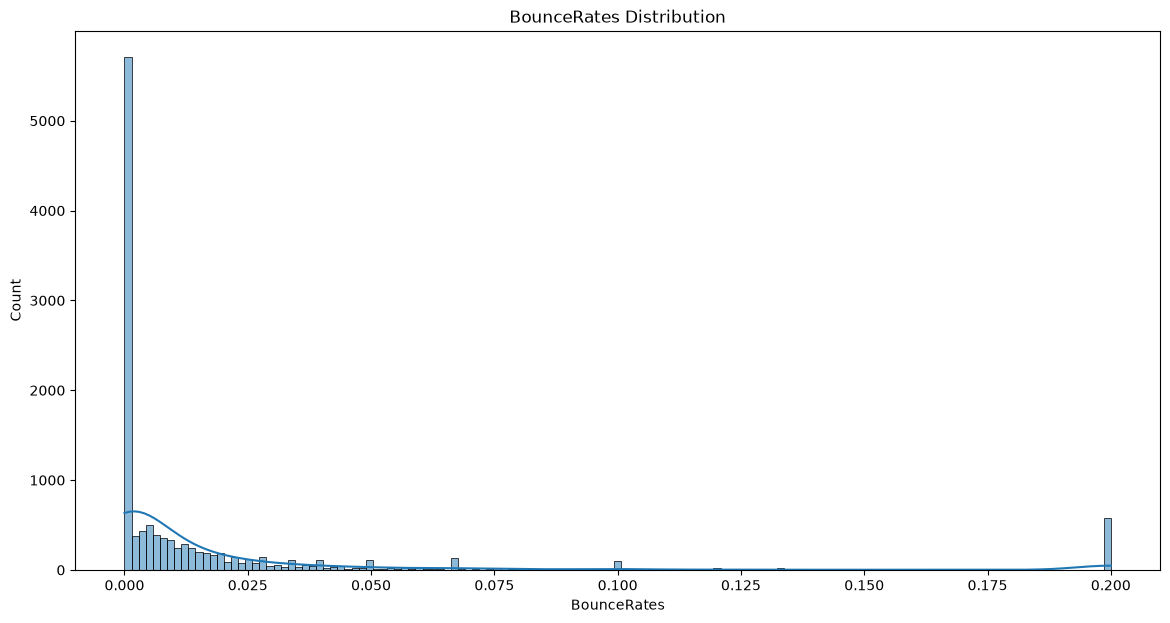

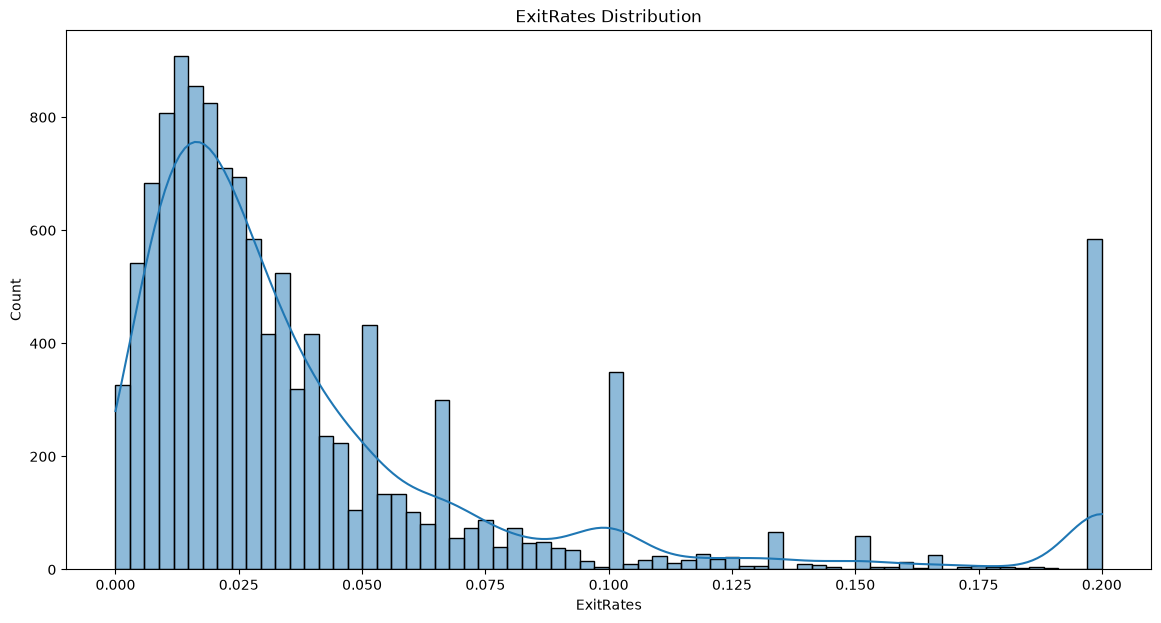

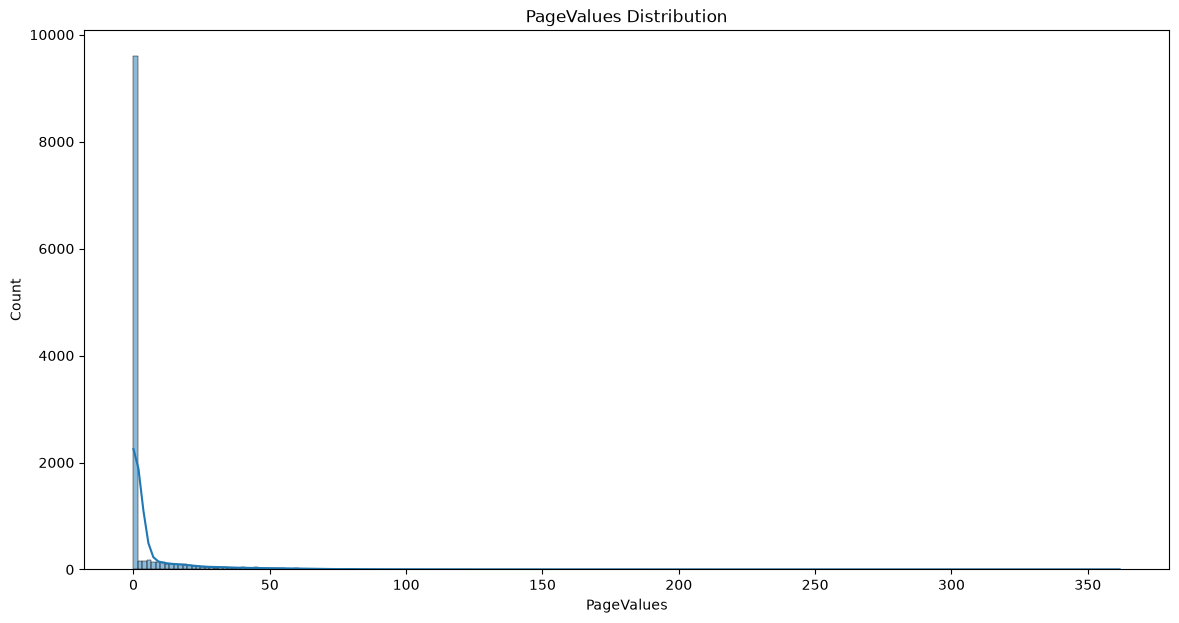

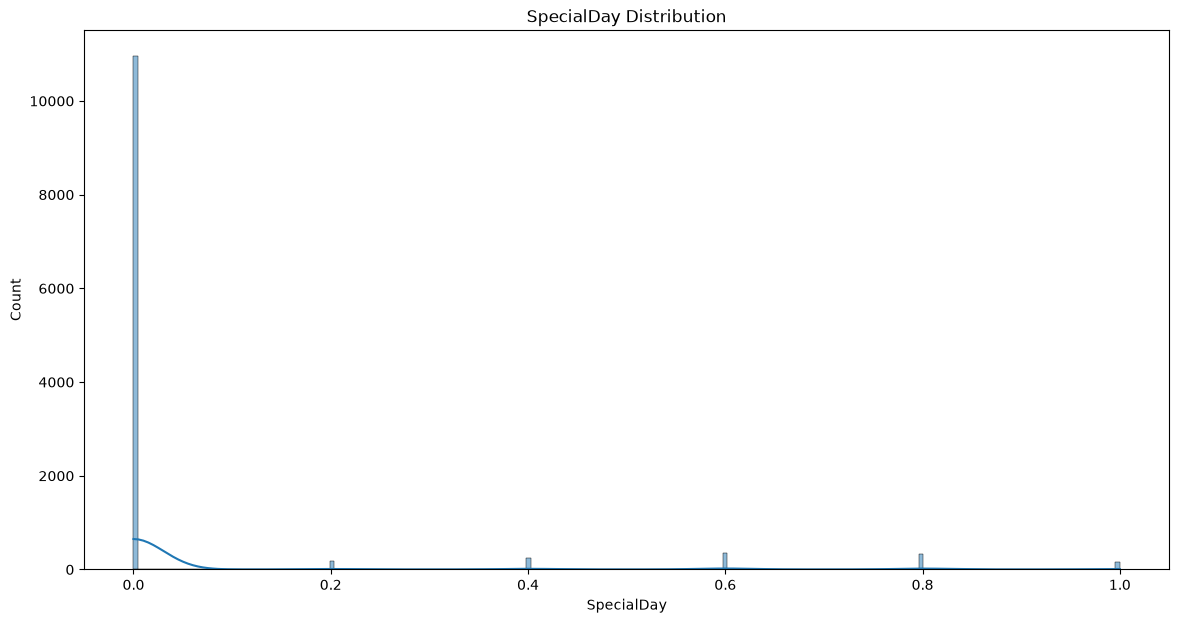

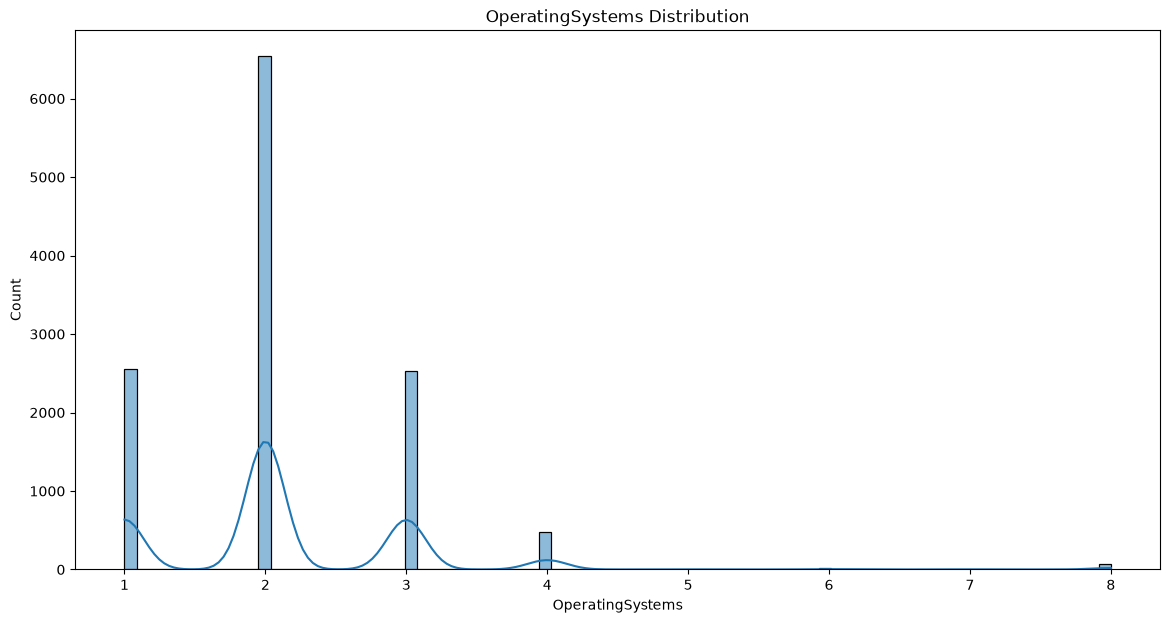

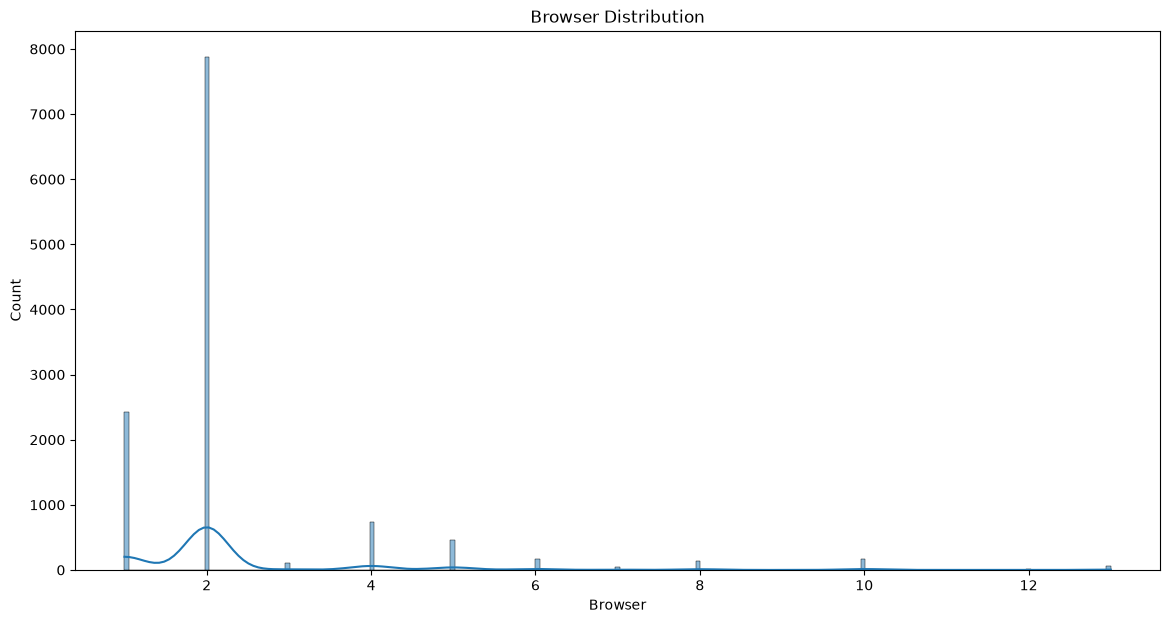

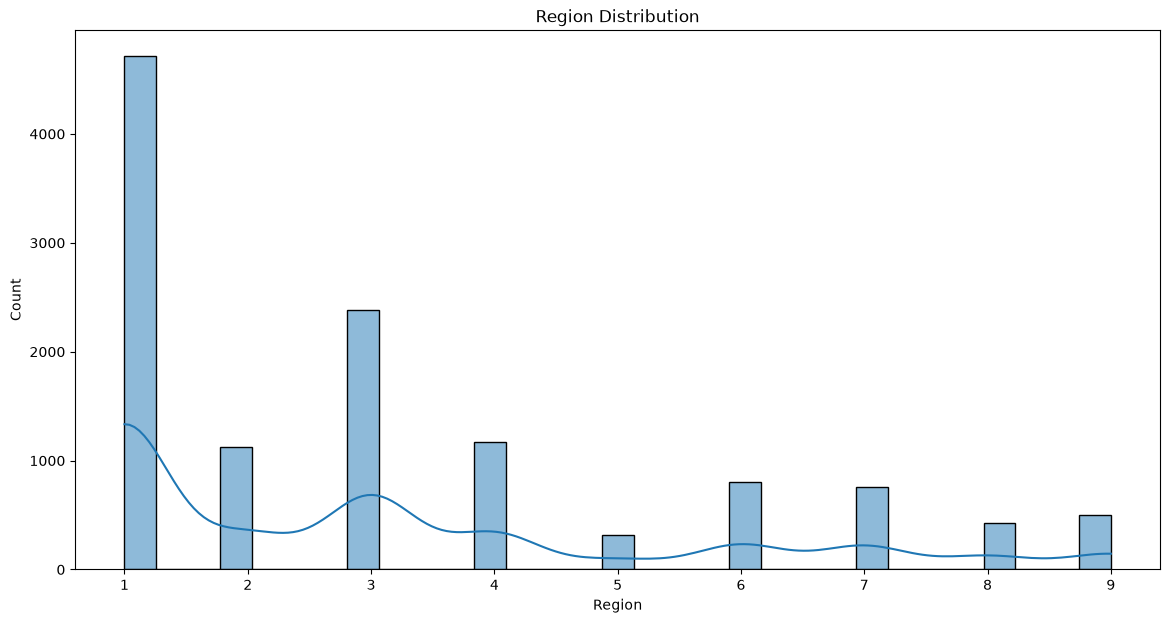

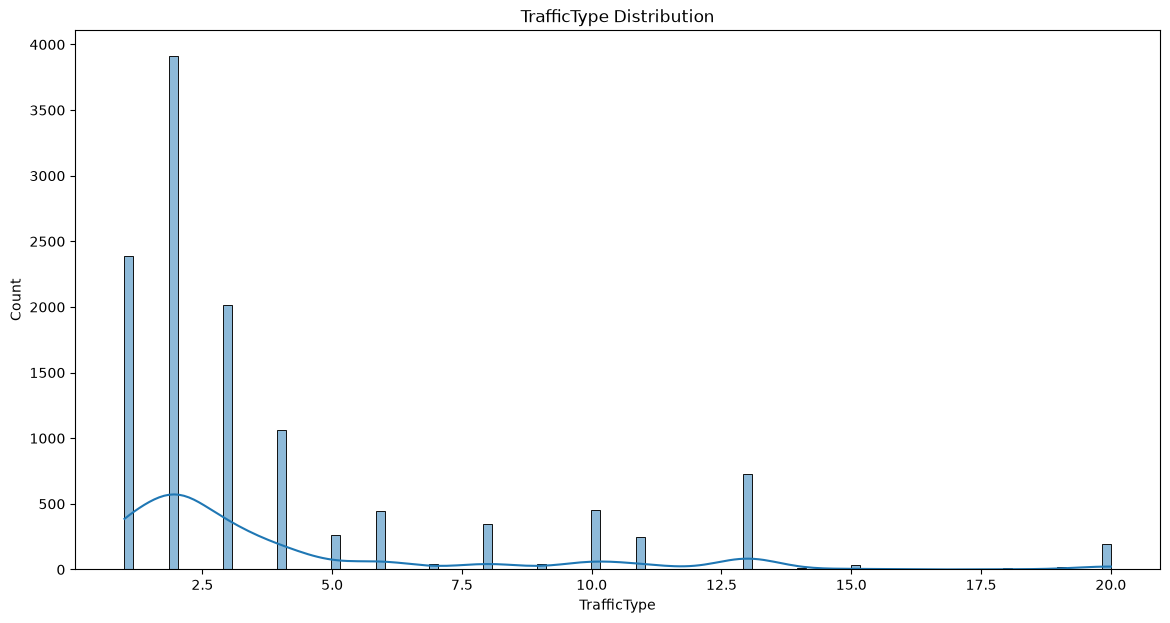

In [10]:
for col in num_cols:
    plt.figure(figsize=(14,7))

    sns.histplot(df[col], kde=True)

    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.show()

In [11]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {outliers}")

Administrative: 404
Administrative_Duration: 1149
Informational: 2631
Informational_Duration: 2405
ProductRelated: 1007
ProductRelated_Duration: 951
BounceRates: 1428
ExitRates: 1325
PageValues: 2730
SpecialDay: 1249
OperatingSystems: 107
Browser: 4322
Region: 505
TrafficType: 2084


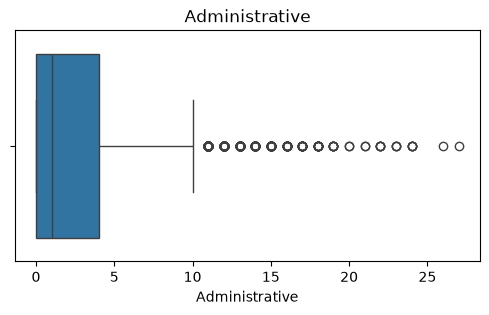

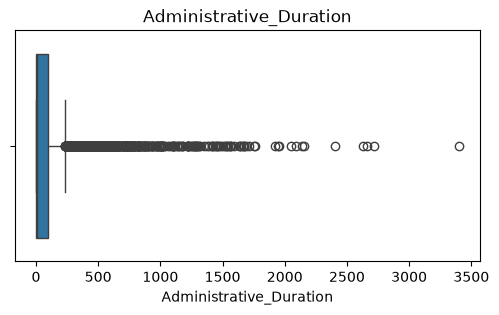

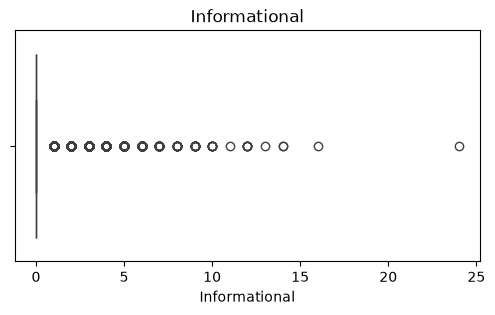

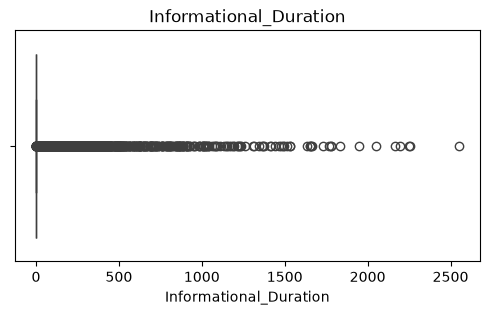

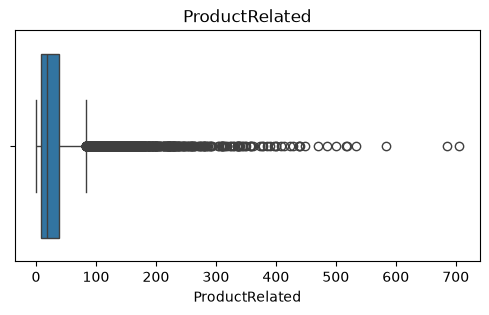

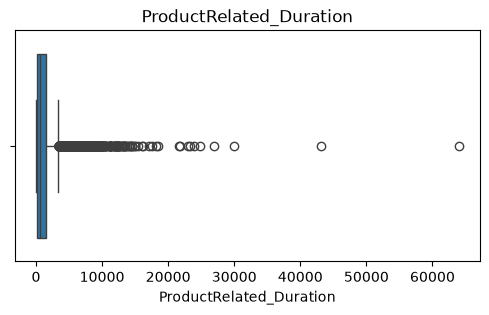

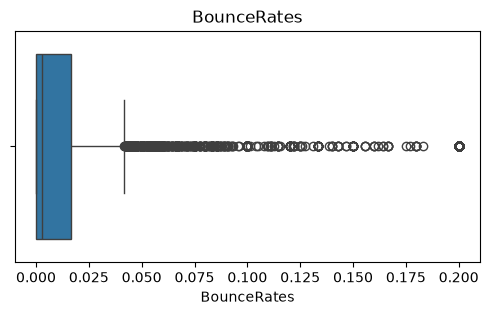

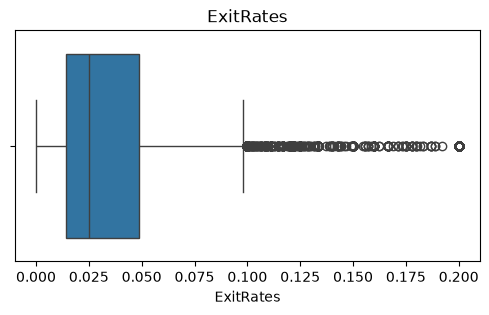

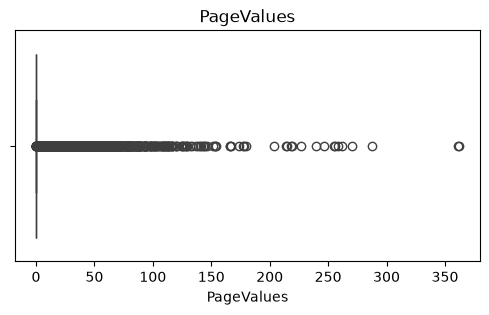

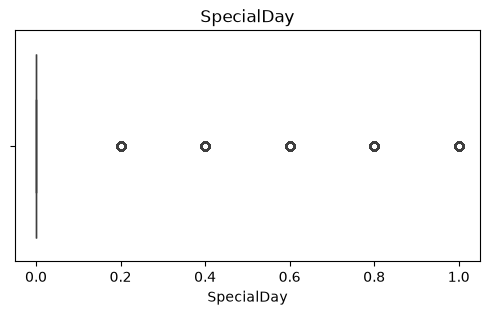

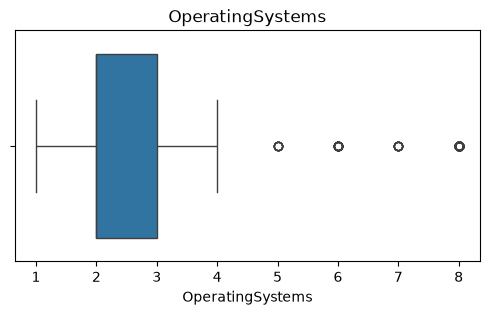

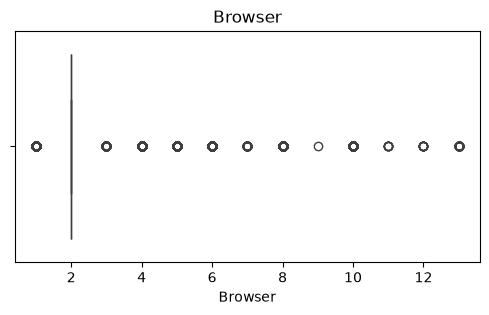

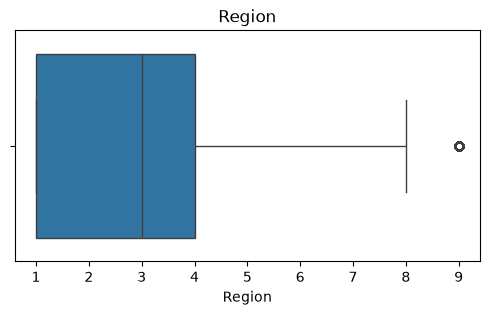

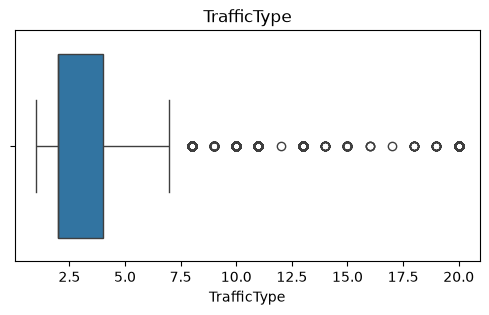

In [12]:
for col in num_cols:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

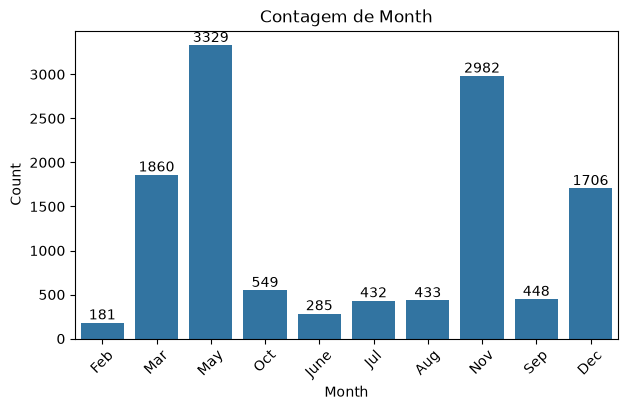

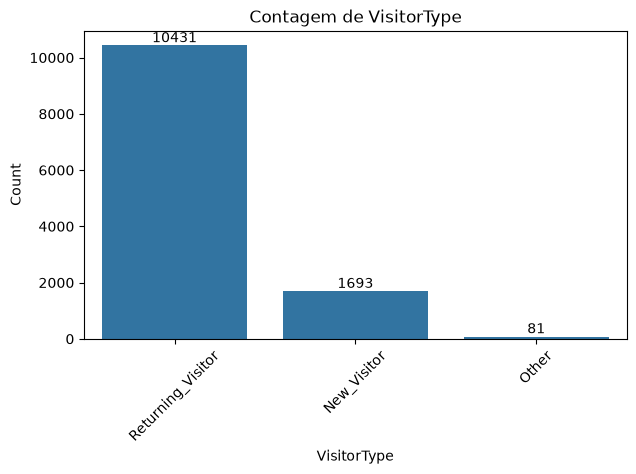

In [13]:
for col in cat_cols:
    
    plt.figure(figsize=(7,4))
    
    ax = sns.countplot(data=df, x=col)
    
    ax.bar_label(ax.containers[0])
    
    plt.title(f"Contagem de {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    
    plt.show()

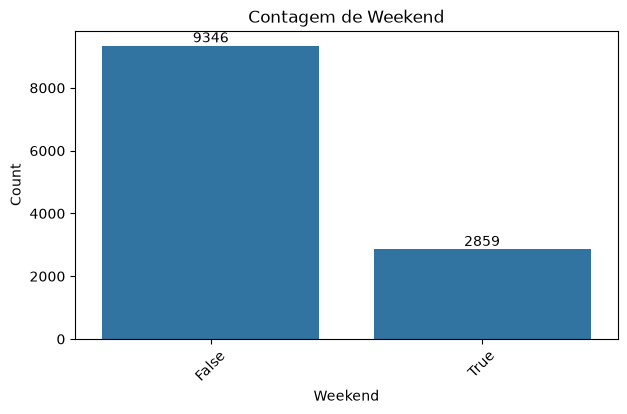

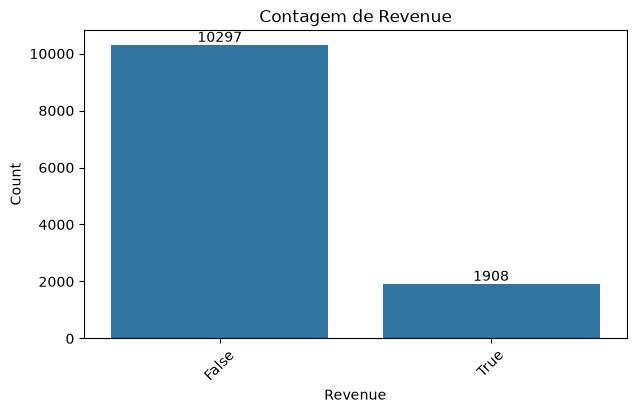

In [14]:
for col in bool_cols:
    
    plt.figure(figsize=(7,4))
    
    ax = sns.countplot(data=df, x=col)
    
    ax.bar_label(ax.containers[0])
    
    plt.title(f"Contagem de {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    
    plt.show()

## 📋 Dicionário de Variáveis

| Nº | Variável | Descrição |
|----|----------|-----------|
| 1 | **Administrative** | Número de páginas do tipo administrativo que o usuário visitou. |
| 2 | **Administrative_Duration** | Tempo gasto nas páginas da categoria administrativa. |
| 3 | **Informational** | Número de páginas do tipo informativo que o usuário visitou. |
| 4 | **Informational_Duration** | Tempo gasto nas páginas da categoria informativa. |
| 5 | **ProductRelated** | Número de páginas relacionadas ao produto que o usuário visitou. |
| 6 | **ProductRelated_Duration** | Tempo gasto nas páginas relacionadas ao produto. |
| 7 | **BounceRates** | Porcentagem de visitantes que entram no site por essa página e saem sem realizar nenhuma outra ação. |
| 8 | **ExitRates** | Porcentagem de visualizações de página do site que terminam naquela página. |
| 9 | **PageValues** | Valor médio da página, calculado em relação ao valor da página de destino e/ou à conclusão de uma compra no e-commerce. |
| 10 | **SpecialDay** | Proximidade da data de navegação em relação a datas especiais ou feriados (ex.: Dia das Mães, Dia dos Namorados). |
| 11 | **Month** | Mês. |
| 12 | **OperatingSystems** | Sistema operacional. |
| 13 | **Browser** | Navegador. |
| 14 | **Region** | Região. |
| 15 | **TrafficType** | Tipo de tráfego. |
| 16 | **VisitorType** | Tipo de visitante. |
| 17 | **Weekend** | Indica se a visita foi no fim de semana. |
| 18 | **Revenue** | **Variável-alvo**: indica se a visita gerou receita. |

In [15]:
# Mapeamento de valores booleanos para 0 e 1
df['Revenue_num'] = df['Revenue'].map({True: 1, False: 0})
# Mapeamento de valores booleanos para 0 e 1
df['Weekend_num'] = df['Weekend'].map({True: 1, False: 0})




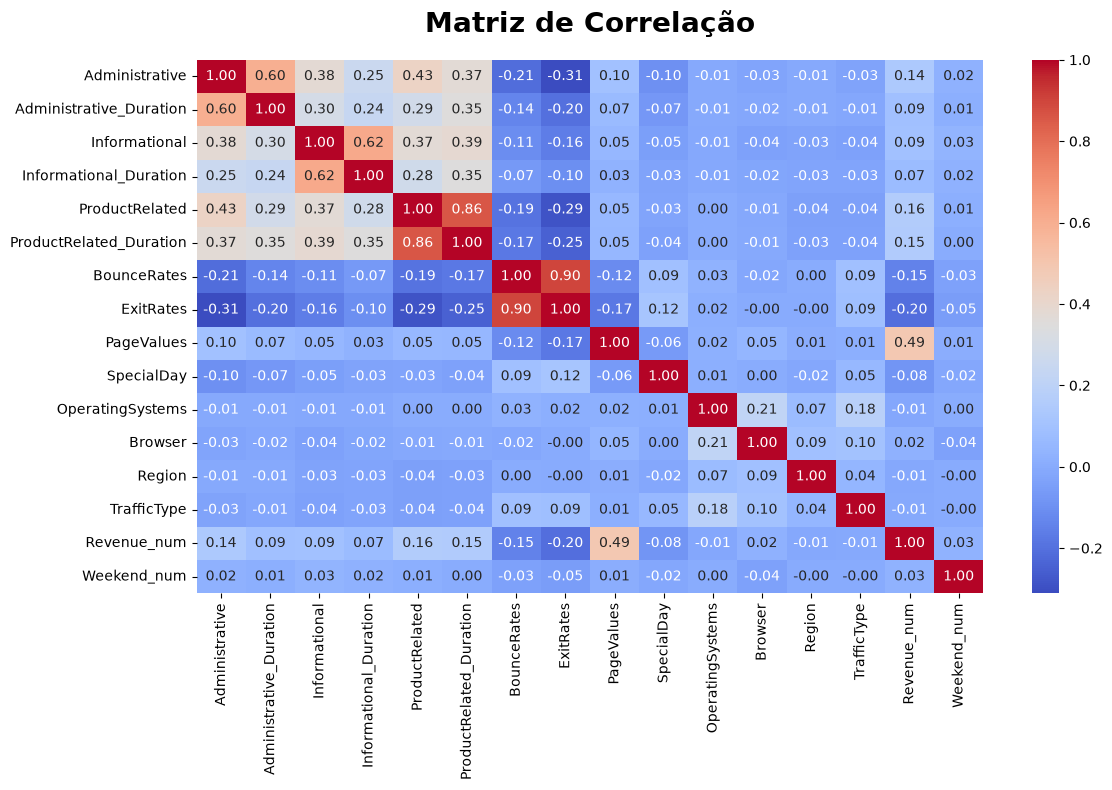

In [16]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include=['int64', 'float64']).corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Matriz de Correlação", fontsize=20, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()


In [17]:
corr_target = (df[num_cols].corrwith(df['Revenue_num']).sort_values(ascending=False))
print(corr_target)

PageValues                 0.491894
ProductRelated             0.156042
ProductRelated_Duration    0.150077
Administrative             0.136330
Informational              0.093626
Administrative_Duration    0.091768
Informational_Duration     0.069358
Browser                    0.024052
TrafficType               -0.005618
Region                    -0.012725
OperatingSystems          -0.014927
SpecialDay                -0.083601
BounceRates               -0.145091
ExitRates                 -0.204320
dtype: float64


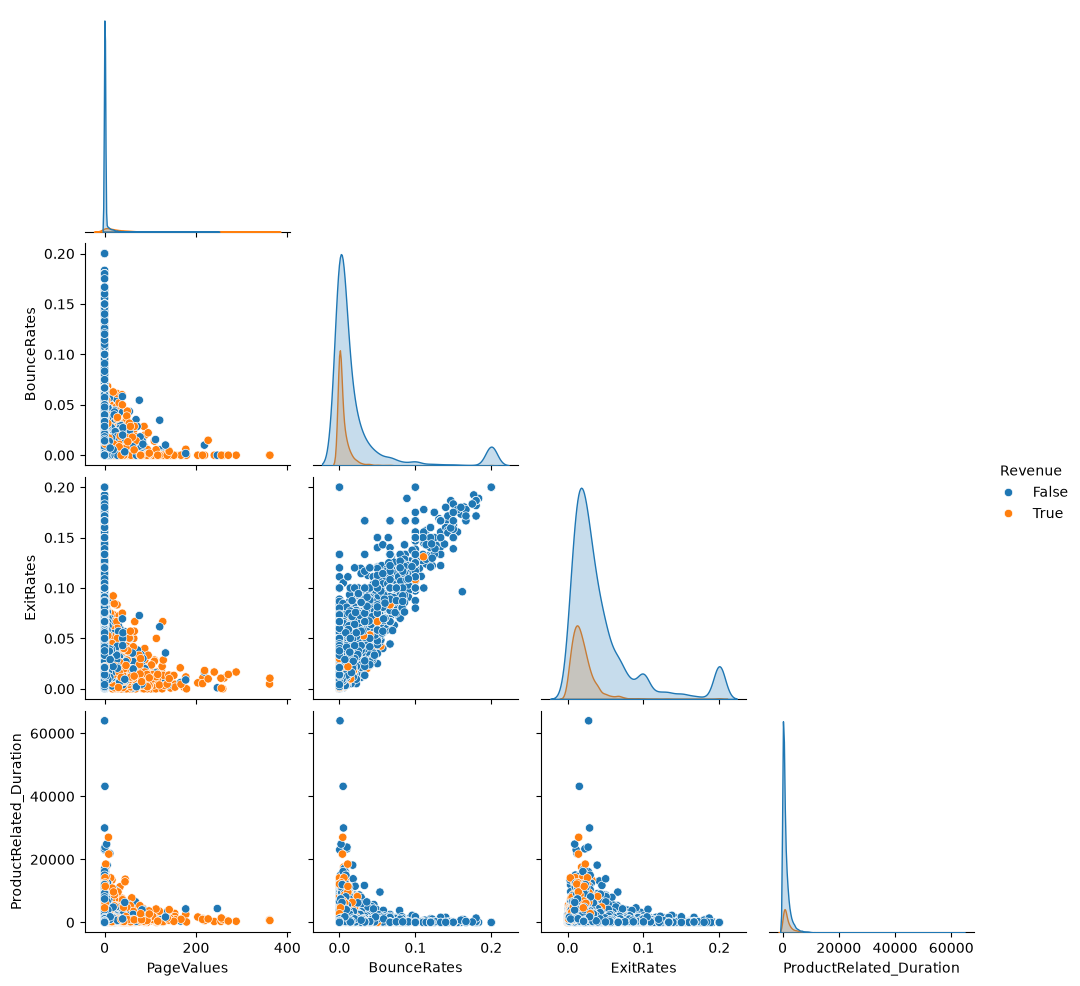

In [18]:
cols = [
    'PageValues',
    'BounceRates',
    'ExitRates',
    'ProductRelated_Duration',
    'Revenue'
]
 
sns.pairplot(
    df[cols],
    hue='Revenue',
    corner=True
)
 
plt.show()

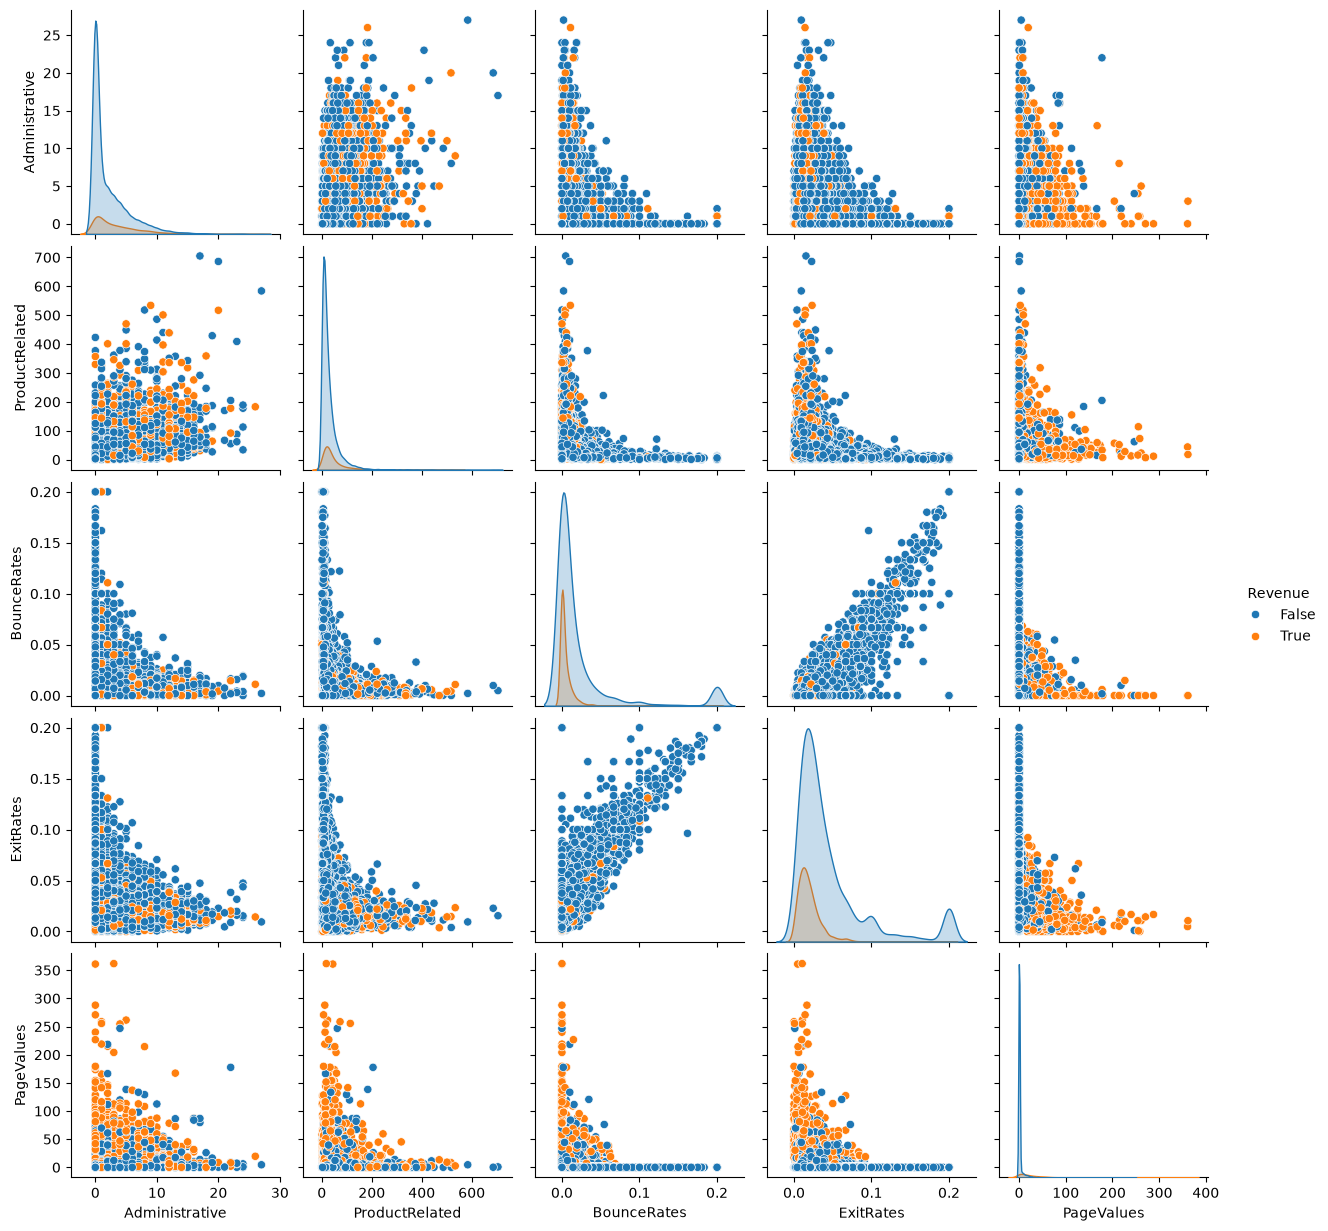

In [19]:
cols = [
    "Administrative",
    "ProductRelated",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "Revenue"
]

sns.pairplot(
    df[cols],
    hue="Revenue"
)

plt.show()

In [20]:
pd.crosstab(
    [df['Month'], df['VisitorType'], df['Weekend']],
    df['Revenue'],
    normalize='index'
) * 100

Revenue                               False      True 
Month VisitorType       Weekend                       
Aug   New_Visitor       False     60.416667  39.583333
                        True      91.666667   8.333333
      Returning_Visitor False     84.429066  15.570934
                        True      86.111111  13.888889
Dec   New_Visitor       False     76.425856  23.574144
                        True      81.690141  18.309859
      Other             False     77.358491  22.641509
                        True      80.000000  20.000000
      Returning_Visitor False     89.990282  10.009718
                        True      91.228070   8.771930
Feb   New_Visitor       False    100.000000   0.000000
      Returning_Visitor False     98.684211   1.315789
                        True      96.428571   3.571429
Jul   New_Visitor       False     80.487805  19.512195
                        True      76.923077  23.076923
      Returning_Visitor False     85.365854  14.634146
                        True      85.714286  14.285714
June  New_Visitor       False     70.833333  29.166667
                        True     100.000000   0.000000
      Other             False    100.000000   0.000000
      Returning_Visitor False     92.018779   7.981221
                        True      87.804878  12.195122
Mar   New_Visitor       False     82.978723  17.021277
                        True      86.813187  13.186813
      Returning_Visitor False     91.700242   8.299758
                        True      86.304910  13.695090
May   New_Visitor       False     72.222222  27.777778
                        True      72.941176  27.058824
      Returning_Visitor False     91.558169   8.441831
                        True      87.917329  12.082671
Nov   New_Visitor       False     68.835616  31.164384
                        True      70.866142  29.133858
      Other             False     85.000000  15.000000
                        True     100.000000   0.000000
      Returning_Visitor False     75.731772  24.268228
                        True      73.867069  26.132931
Oct   New_Visitor       False     75.000000  25.000000
                        True      82.500000  17.500000
      Returning_Visitor False     80.062305  19.937695
                        True      77.884615  22.115385
Sep   New_Visitor       False     76.744186  23.255814
                        True      63.636364  36.363636
      Returning_Visitor False     83.458647  16.541353
                        True      81.081081  18.918919

In [21]:
# Mapeamento de valores de mês para números inteiros
df['Month'] = df['Month'].map({
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'June': 6,
    'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
})

In [22]:
# Mapeamento de valores de tipo de visitante para números inteiros
df['VisitorType'] = df['VisitorType'].map({
    'Returning_Visitor': 1, 'New_Visitor': 0, 'Other': 2
})

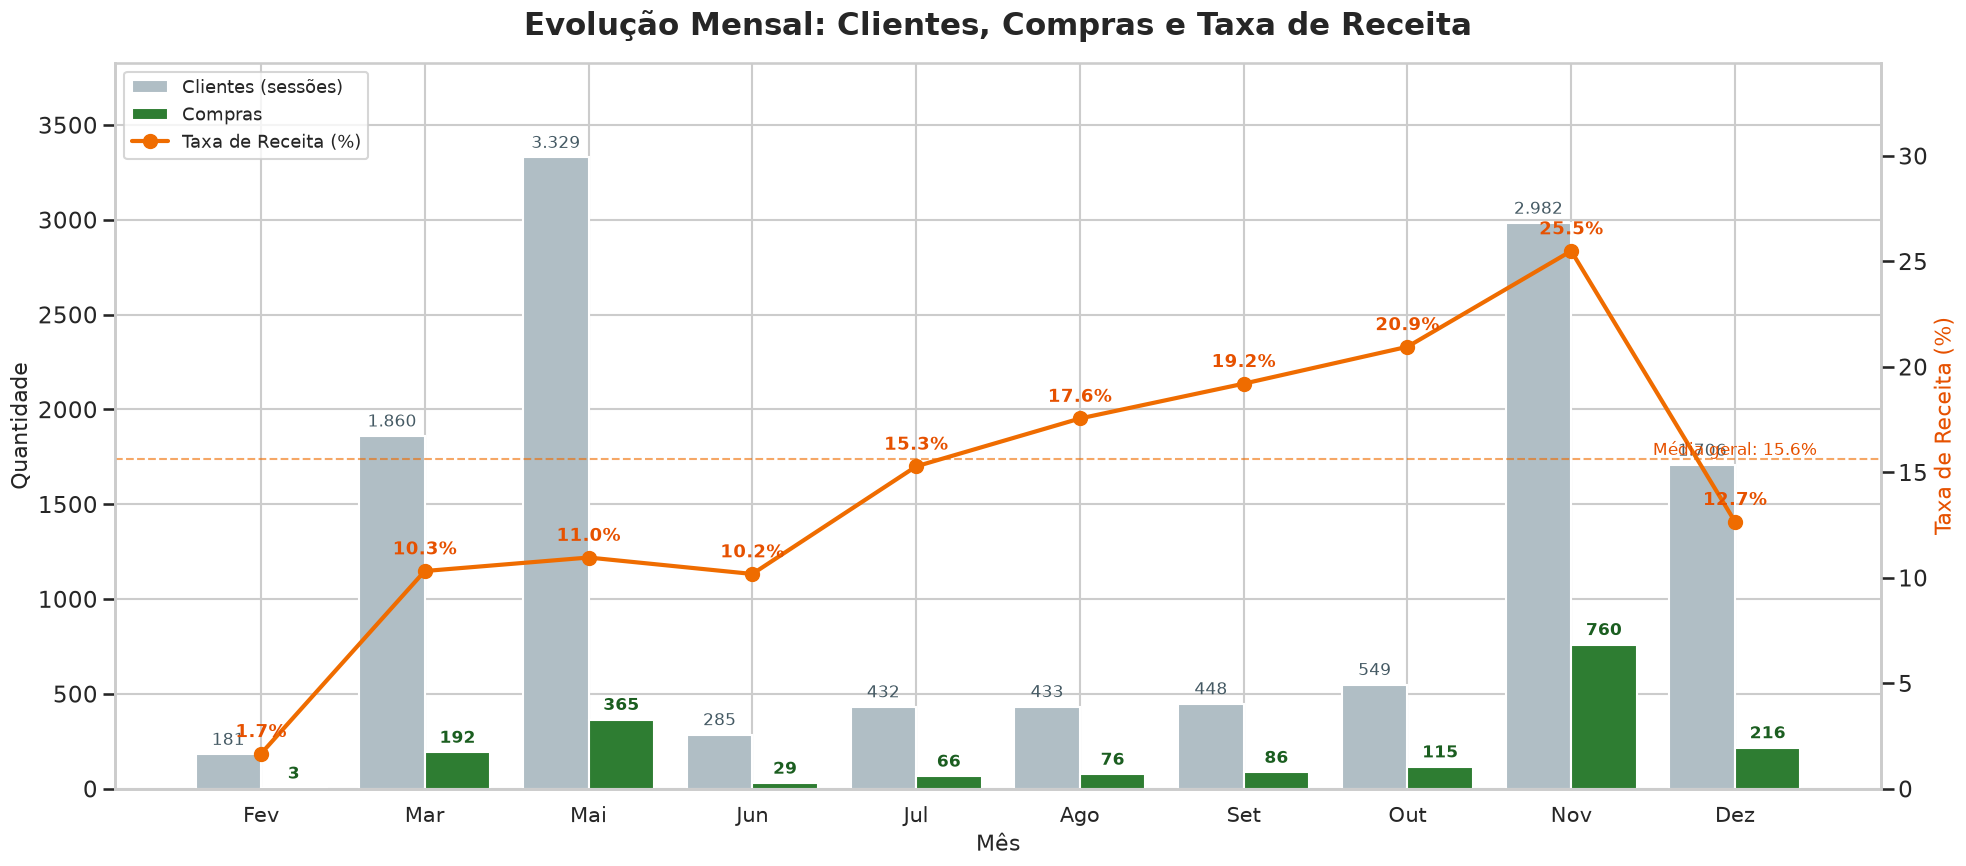

In [23]:

# Análise de Receita por Mês
sns.set_theme(style='whitegrid', context='talk')


# Agrupamento por mês, contando clientes e somando compras
analise_mes = (
    df.groupby('Month')['Revenue_num']
      .agg(clientes='count', compras='sum')
)

codigos = set(analise_mes.index)

# Verifica se os códigos de mês estão dentro do intervalo de 1 a 12 e se não há código 0
if codigos <= set(range(1, 13)) and 0 not in codigos:

    nomes = {1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun',
             7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'}
    ordem = sorted(codigos)
else:

    nomes = {0: 'Ago', 1: 'Dez', 2: 'Fev', 3: 'Jul', 4: 'Jun',
             5: 'Mar', 6: 'Mai', 7: 'Nov', 8: 'Out', 9: 'Set'}
    ordem = [2, 5, 6, 4, 3, 0, 9, 8, 7, 1]  # Fev → Dez


# Reindexa o DataFrame para garantir a ordem correta dos meses
analise_mes = analise_mes.reindex(ordem)
analise_mes.index = [nomes[c] for c in ordem]
analise_mes['taxa_revenue'] = (analise_mes['compras'] / analise_mes['clientes'] * 100).round(2)

taxa_geral = df['Revenue_num'].mean() * 100

# Função para formatar números com separador de milhar
def fmt_num(n):
    return f'{int(n):,}'.replace(',', '.')  

x = np.arange(len(analise_mes))
largura = 0.4

fig, ax = plt.subplots(figsize=(20, 9))


barras_cli = ax.bar(x - largura / 2, analise_mes['clientes'], largura,
                    color='#B0BEC5', label='Clientes (sessões)')
barras_comp = ax.bar(x + largura / 2, analise_mes['compras'], largura,
                     color='#2E7D32', label='Compras')

ax.bar_label(barras_cli, labels=[fmt_num(v) for v in analise_mes['clientes']],
             padding=4, fontsize=12, color='#455A64')
ax.bar_label(barras_comp, labels=[fmt_num(v) for v in analise_mes['compras']],
             padding=4, fontsize=12, fontweight='bold', color='#1B5E20')

ax.set_xticks(x)
ax.set_xticklabels(analise_mes.index, fontsize=15)
ax.set_xlabel('Mês', fontsize=16)
ax.set_ylabel('Quantidade', fontsize=16)
ax.set_ylim(0, analise_mes['clientes'].max() * 1.15)


ax2 = ax.twinx()
ax2.plot(x, analise_mes['taxa_revenue'], color='#EF6C00', marker='o',
         markersize=10, linewidth=3, label='Taxa de Receita (%)')

for xi, taxa in zip(x, analise_mes['taxa_revenue']):
    ax2.annotate(f'{taxa:.1f}%', (xi, taxa), textcoords='offset points',
                 xytext=(0, 12), ha='center', fontsize=13,
                 fontweight='bold', color='#E65100')

ax2.axhline(taxa_geral, color='#EF6C00', linestyle='--', linewidth=1.5, alpha=0.6)
ax2.text(x[-1] + 0.5, taxa_geral, f'Média geral: {taxa_geral:.1f}%',
         ha='right', va='bottom', fontsize=12, color='#E65100')

ax2.set_ylabel('Taxa de Receita (%)', fontsize=16, color='#E65100')
ax2.set_ylim(0, analise_mes['taxa_revenue'].max() * 1.35)
ax2.grid(False)


h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', fontsize=13, frameon=True)

ax.set_title('Evolução Mensal: Clientes, Compras e Taxa de Receita',
             fontsize=22, fontweight='bold', pad=20)
sns.despine(ax=ax, right=False)
fig.tight_layout()
plt.show()

In [24]:
# Análise de Receita por Tipo de Visitante
analise_revenue = df.groupby('VisitorType')['Revenue_num'].agg(
    clientes='count', revenue='sum', taxa_revenue=lambda x: (x.sum() / x.count()) * 100
)

analise_revenue['taxa_rejeição'] = df['BounceRates'].groupby(df['VisitorType']).mean() * 100
analise_revenue['taxa_saida'] = df['ExitRates'].groupby(df['VisitorType']).mean() * 100

analise_revenue.round(2).sort_values(by='taxa_revenue', ascending=False)


,clientes,revenue,taxa_revenue,taxa_rejeição,taxa_saida
VisitorType,,,,,
0,1693,422,24.93,0.51,2.06
2,81,16,19.75,3.06,5.66
1,10431,1470,14.09,2.28,4.47


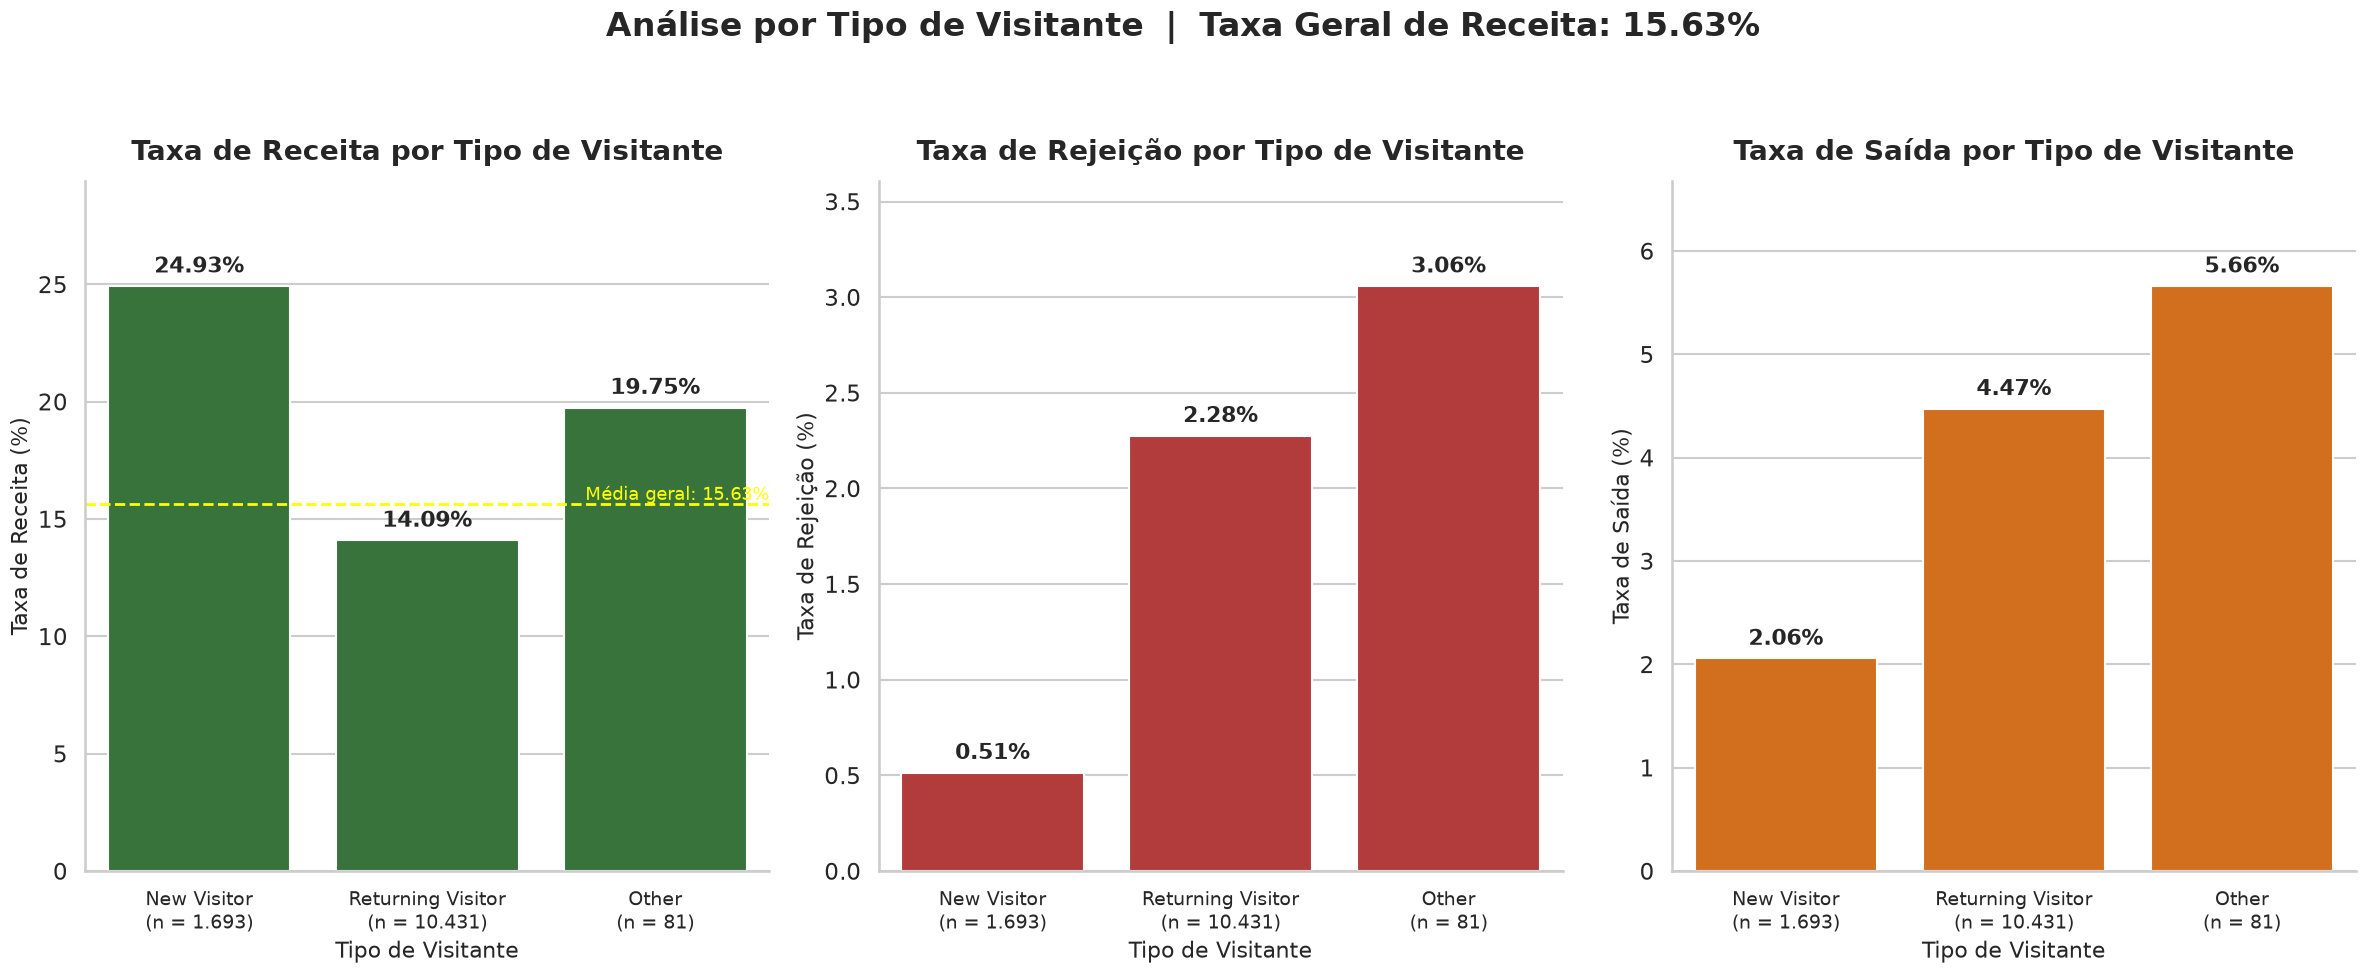

In [25]:
sns.set_theme(style='whitegrid', context='talk')

taxa_geral = df['Revenue'].mean() * 100

# Traduz o código numérico para o nome do tipo de visitante
mapa_visitante = {0: 'New Visitor', 1: 'Returning Visitor', 2: 'Other'}
nomes = [mapa_visitante.get(i, str(i)) for i in analise_revenue.index]

# Quantidade de visitantes: já existe na coluna 'clientes'
qtd_visitantes = analise_revenue['clientes']

def fmt_num(n):
    return f'{int(n):,}'.replace(',', '.')  # 10551 -> 10.551

metricas = [
    ('taxa_revenue',  'Taxa de Receita',  '#2E7D32'),
    ('taxa_rejeição', 'Taxa de Rejeição', '#C62828'),
    ('taxa_saida',    'Taxa de Saída',    '#EF6C00'),
]

fig, axes = plt.subplots(1, 3, figsize=(24, 10))

for ax, (coluna, titulo, cor) in zip(axes, metricas):
    valores = analise_revenue[coluna].values

    # order=nomes garante que barras e rótulos fiquem na mesma ordem
    sns.barplot(x=nomes, y=valores, order=nomes, ax=ax, color=cor)

    # Valor da taxa em cima de cada barra
    ax.bar_label(ax.containers[0], labels=[f'{v:.2f}%' for v in valores],
                 padding=6, fontsize=16, fontweight='bold')

    # Nome + quantidade embaixo de cada barra
    ax.set_xticks(range(len(nomes)))
    ax.set_xticklabels([f'{nome}\n(n = {fmt_num(n)})'
                        for nome, n in zip(nomes, qtd_visitantes)],
                       fontsize=14)

    ax.set_title(f'{titulo} por Tipo de Visitante', fontsize=20, fontweight='bold', pad=15)
    ax.set_xlabel('Tipo de Visitante', fontsize=16)
    ax.set_ylabel(f'{titulo} (%)', fontsize=16)
    ax.set_ylim(0, valores.max() * 1.18)
    sns.despine(ax=ax)

# Linha de referência com a taxa geral no gráfico de receita
axes[0].axhline(taxa_geral, color='yellow', linestyle='--', linewidth=2)
axes[0].text(len(nomes) - 0.5, taxa_geral, f'Média geral: {taxa_geral:.2f}%',
             ha='right', va='bottom', fontsize=13, color='yellow')

fig.suptitle(f'Análise por Tipo de Visitante  |  Taxa Geral de Receita: {taxa_geral:.2f}%',
             fontsize=24, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# Feature Engineering

In [26]:
# TotalPages é a soma das páginas visitadas de cada tipo
df['TotalPages'] = (
    df['Administrative']
    + df['Informational']
    + df['ProductRelated']
)

In [27]:
# TotalDuration é a soma das durações de cada tipo de página visitada
df["TotalDuration"] = (
    df["Administrative_Duration"]
    + df["Informational_Duration"]
    + df["ProductRelated_Duration"]
)

In [28]:
# ValuePerProduct é o valor total da página dividido pelo número de páginas do tipo produto
df["ValuePerProduct"] = (
    df["PageValues"]/
    (df["ProductRelated"] + 1)
)

In [29]:
# PageValuePerDuration é o valor total da página dividido pelo tempo total gasto em todas as páginas
df["PageValuePerDuration"] = (
    df["PageValues"] /
    (df["TotalDuration"] + 1)
)

In [30]:
# ProductFocusRatio é a razão entre o número de páginas do tipo produto e o número total de páginas visitadas
df['ProductFocusRatio'] = (df['ProductRelated']/ (df['TotalPages'] + 1))

In [31]:
# ProductTimeRatio é a razão entre o tempo gasto em páginas do tipo produto e o número de páginas do tipo produto
df['ProductTimeRatio'] = (df['ProductRelated_Duration']* (df['ProductRelated'] + 1))

In [32]:
# BounceExitDiff é a soma das taxas de saída e rejeição, onde um valor menor está associado a uma maior chance de compra.
df["BounceExitDiff"] = (
    df["ExitRates"] +
    df["BounceRates"]
) 


In [33]:
new_features = [
    "TotalPages",
    "TotalDuration",
    "ValuePerProduct",
    "ProductFocusRatio",
    "ProductTimeRatio",
    "BounceExitDiff",
    "PageValuePerDuration"
]

corr = (
    df[new_features + ["Revenue"]]
    .corr(numeric_only=True)["Revenue"]
    .sort_values(ascending=False)*100
)

print(corr)

Revenue                 100.000000
ValuePerProduct          38.169721
PageValuePerDuration     28.174082
TotalPages               16.153516
TotalDuration            15.372045
ProductFocusRatio         8.101612
ProductTimeRatio          7.036009
BounceExitDiff          -17.944405
Name: Revenue, dtype: float64


In [34]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} valores únicos")

Administrative: 27 valores únicos
Administrative_Duration: 3335 valores únicos
Informational: 17 valores únicos
Informational_Duration: 1258 valores únicos
ProductRelated: 311 valores únicos
ProductRelated_Duration: 9551 valores únicos
BounceRates: 1872 valores únicos
ExitRates: 4777 valores únicos
PageValues: 2704 valores únicos
SpecialDay: 6 valores únicos
Month: 10 valores únicos
OperatingSystems: 8 valores únicos
Browser: 13 valores únicos
Region: 9 valores únicos
TrafficType: 20 valores únicos
VisitorType: 3 valores únicos
Weekend: 2 valores únicos
Revenue: 2 valores únicos
Revenue_num: 2 valores únicos
Weekend_num: 2 valores únicos
TotalPages: 314 valores únicos
TotalDuration: 9749 valores únicos
ValuePerProduct: 2728 valores únicos
PageValuePerDuration: 2731 valores únicos
ProductFocusRatio: 1268 valores únicos
ProductTimeRatio: 10634 valores únicos
BounceExitDiff: 5489 valores únicos


In [35]:
df = df.drop(['Revenue_num', 'Weekend_num'], axis=1)

In [36]:
df.info()

<class 'pandas.DataFrame'>
Index: 12205 entries, 0 to 12329
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12205 non-null  int64  
 1   Administrative_Duration  12205 non-null  float64
 2   Informational            12205 non-null  int64  
 3   Informational_Duration   12205 non-null  float64
 4   ProductRelated           12205 non-null  int64  
 5   ProductRelated_Duration  12205 non-null  float64
 6   BounceRates              12205 non-null  float64
 7   ExitRates                12205 non-null  float64
 8   PageValues               12205 non-null  float64
 9   SpecialDay               12205 non-null  float64
 10  Month                    12205 non-null  int64  
 11  OperatingSystems         12205 non-null  int64  
 12  Browser                  12205 non-null  int64  
 13  Region                   12205 non-null  int64  
 14  TrafficType              12205 non-nul

In [37]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,VisitorType,Weekend,Revenue,TotalPages,TotalDuration,ValuePerProduct,PageValuePerDuration,ProductFocusRatio,ProductTimeRatio,BounceExitDiff
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,False,False,1,0.000000,0.0,0.0,0.500000,0.0,0.40
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,False,False,2,64.000000,0.0,0.0,0.666667,192.0,0.10
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,False,False,1,0.000000,0.0,0.0,0.500000,0.0,0.40
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,1,False,False,2,2.666667,0.0,0.0,0.666667,8.0,0.19
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,True,False,10,627.500000,0.0,0.0,0.909091,6902.5,0.07


In [38]:
from sklearn.preprocessing import LabelEncoder


In [39]:
# Encode das colunas categóricas (bool) para númericas
le = LabelEncoder()

df['Weekend'] = le.fit_transform(df['Weekend'])
df['Revenue'] = le.fit_transform(df['Revenue'])

In [40]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,VisitorType,Weekend,Revenue,TotalPages,TotalDuration,ValuePerProduct,PageValuePerDuration,ProductFocusRatio,ProductTimeRatio,BounceExitDiff
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,0,0,1,0.000000,0.0,0.0,0.500000,0.0,0.40
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,1,0,0,2,64.000000,0.0,0.0,0.666667,192.0,0.10
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,1,0,0,1,0.000000,0.0,0.0,0.500000,0.0,0.40
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,1,0,0,2,2.666667,0.0,0.0,0.666667,8.0,0.19
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,1,1,0,10,627.500000,0.0,0.0,0.909091,6902.5,0.07


# Modelagem

In [41]:
# desembaralha o DataFrame para evitar qualquer viés na ordem dos dados
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

In [42]:
# Separa as features (X) e o target (y)
x = df.drop('Revenue', axis=1)
y = df['Revenue']

In [51]:
# Importação de Bibliotecas para Modelagem
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Importação de Bibliotecas para Pré-processamento e Avaliação
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from imblearn.pipeline import make_pipeline as make_imb_pipeline

In [52]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y, shuffle=True)

In [53]:
lr = make_imb_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42, max_iter=1000)
)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Regressão Logística Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_lr):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Regressão Logística Performance:
Accuracy: 0.8861
Precision: 0.7430
Recall: 0.4162
F1 Score: 0.5336

Confusion Matrix:
[[2004   55]
 [ 223  159]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.97      0.94      2059
           1       0.74      0.42      0.53       382

    accuracy                           0.89      2441
   macro avg       0.82      0.69      0.73      2441
weighted avg       0.88      0.89      0.87      2441



In [54]:
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("Antes do SMOTE:")
print(y_train.value_counts())
print("\nDepois do SMOTE:")
print(y_train_smote.value_counts())

Antes do SMOTE:
Revenue
0    8238
1    1526
Name: count, dtype: int64

Depois do SMOTE:
Revenue
1    8238
0    8238
Name: count, dtype: int64


In [55]:
lr_smote = make_imb_pipeline(
    StandardScaler(),
    SMOTE(random_state=42),
    LogisticRegression(random_state=42, max_iter=1000)
)

lr_smote.fit(X_train, y_train)

y_pred_lr_smote = lr_smote.predict(X_test)

print("Regressão Logística com Smote Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr_smote):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr_smote):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr_smote):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_lr_smote):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr_smote))


Regressão Logística com Smote Performance:
Accuracy: 0.8570
Precision: 0.5319
Recall: 0.7199
F1 Score: 0.6118

Confusion Matrix:
[[1817  242]
 [ 107  275]]

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.88      0.91      2059
           1       0.53      0.72      0.61       382

    accuracy                           0.86      2441
   macro avg       0.74      0.80      0.76      2441
weighted avg       0.88      0.86      0.87      2441



In [56]:
print("\n============================== Comparação de Modelos ==============================\n")

print("Modelo: Regressão Logística sem SMOTE")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_lr):.4f}")  

print("\nModelo: Regressão Logística com SMOTE")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr_smote):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr_smote):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr_smote):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_lr_smote):.4f}")  


============================== Comparação de Modelos ==============================

Modelo: Regressão Logística sem SMOTE
Accuracy: 0.8861
Precision: 0.7430
Recall: 0.4162
F1 Score: 0.5336

Modelo: Regressão Logística com SMOTE
Accuracy: 0.8570
Precision: 0.5319
Recall: 0.7199
F1 Score: 0.6118


In [57]:
from sklearn.model_selection import cross_validate, StratifiedKFold

In [58]:
lr_balanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000)
)

modelos = {
    "LR sem SMOTE": lr,
    "LR com SMOTE": lr_smote,
    "LR balanced": lr_balanced,
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ["precision", "recall", "f1", "average_precision"]

for nome, modelo in modelos.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas)
    print(f"\n{nome}")
    for m in metricas:
        s = res[f"test_{m}"]
        print(f"  {m:18s} {s.mean():.4f} ± {s.std():.4f}")


LR sem SMOTE
  precision          0.7701 ± 0.0192
  recall             0.3814 ± 0.0130
  f1                 0.5100 ± 0.0136
  average_precision  0.6568 ± 0.0164

LR com SMOTE
  precision          0.5321 ± 0.0136
  recall             0.7575 ± 0.0098
  f1                 0.6250 ± 0.0088
  average_precision  0.6646 ± 0.0174

LR balanced
  precision          0.5304 ± 0.0148
  recall             0.7582 ± 0.0097
  f1                 0.6240 ± 0.0107
  average_precision  0.6647 ± 0.0176


### Escolha do baseline

Para definir o modelo baseline, comparamos três variações de Regressão Logística
(todas com `StandardScaler`), usando validação cruzada estratificada com 5 folds
no conjunto de treino:

| Modelo | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|
| LR sem tratamento | 0.7701 ± 0.0192 | 0.3814 ± 0.0130 | 0.5100 ± 0.0136 | 0.6568 ± 0.0164 |
| LR com SMOTE | 0.5321 ± 0.0136 | 0.7575 ± 0.0098 | 0.6250 ± 0.0088 | 0.6646 ± 0.0174 |
| LR com `class_weight="balanced"` | 0.5304 ± 0.0148 | 0.7582 ± 0.0097 | 0.6240 ± 0.0107 | 0.6647 ± 0.0176 |

**Principais observações:**

- O modelo sem tratamento do desbalanceamento tem recall de apenas 0.38, ou seja,
  deixa de identificar cerca de 62% das sessões que resultam em compra.
- SMOTE e `class_weight="balanced"` tiveram desempenho equivalente: as diferenças
  ficam bem abaixo do desvio-padrão entre os folds.
- A PR-AUC é praticamente igual nos três modelos. Isso indica que as técnicas de
  balanceamento não aumentaram a capacidade do modelo de separar as classes; elas
  apenas deslocaram o ponto de corte, trocando precisão por recall.

**Decisão:** adotamos a **Regressão Logística com `class_weight="balanced"` e
parâmetros padrão** como baseline. Em relação ao SMOTE, ela tem desempenho equivalente
e é mais simples: não gera dados sintéticos (o que evita interpolar valores inválidos
em variáveis categóricas), não depende de bibliotecas adicionais e é mais fácil de
interpretar.

Como a PR-AUC ficou em torno de 0.66 mesmo com tratamento do desbalanceamento, o limite parece estar na natureza linear do modelo. Isso motiva o
teste de modelos baseados em árvores, capazes de capturar relações não lineares entre
as variáveis.

# Árvore de Decisão

In [64]:
# Decision Tree Classifier
dt = make_pipeline(
    DecisionTreeClassifier(random_state=42)
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("\nDecision Tree Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_dt):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


Decision Tree Performance:
Accuracy: 0.8648
Precision: 0.5653
Recall: 0.5890
F1-Score: 0.5769

Confusion Matrix:
[[1886  173]
 [ 157  225]]

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92      2059
           1       0.57      0.59      0.58       382

    accuracy                           0.86      2441
   macro avg       0.74      0.75      0.75      2441
weighted avg       0.87      0.86      0.87      2441



In [65]:
dt_smote = make_imb_pipeline(
    SMOTE(random_state=42),
    DecisionTreeClassifier(random_state=42)
)

dt_smote.fit(X_train, y_train)

y_pred_dt_smote = dt_smote.predict(X_test)

print("\nDecision Tree with SMOTE Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt_smote):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt_smote):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_dt_smote):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_dt_smote):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt_smote))


Decision Tree with SMOTE Performance:
Accuracy: 0.8562
Precision: 0.5335
Recall: 0.6466
F1-Score: 0.5846

Confusion Matrix:
[[1843  216]
 [ 135  247]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.90      0.91      2059
           1       0.53      0.65      0.58       382

    accuracy                           0.86      2441
   macro avg       0.73      0.77      0.75      2441
weighted avg       0.87      0.86      0.86      2441



In [70]:
print("\n============================== Comparação de Modelos ==============================\n")

print("Modelo: Decision Tree sem SMOTE")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_dt):.4f}")  

print("\nModelo: Decision Tree com SMOTE")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt_smote):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt_smote):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_dt_smote):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_dt_smote):.4f}")  


============================== Comparação de Modelos ==============================

Modelo: Decision Tree sem SMOTE
Accuracy: 0.8648
Precision: 0.5653
Recall: 0.5890
F1 Score: 0.5769

Modelo: Decision Tree com SMOTE
Accuracy: 0.8562
Precision: 0.5335
Recall: 0.6466
F1 Score: 0.5846


In [71]:
from sklearn.model_selection import GridSearchCV

dt = DecisionTreeClassifier(class_weight="balanced", random_state=42)

param_grid_dt = {
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_leaf": [1, 5, 20, 50, 100, 200],
    "criterion": ["gini", "entropy"],
}

grid_dt = GridSearchCV(
    dt, param_grid_dt, cv=cv,
    scoring="average_precision", n_jobs=-1,
)
grid_dt.fit(X_train, y_train)

print("Melhores parâmetros:", grid_dt.best_params_)
print(f"PR-AUC (CV): {grid_dt.best_score_:.4f}")

Melhores parâmetros: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 50}
PR-AUC (CV): 0.7018


In [73]:
dt_best = grid_dt.best_estimator_

modelos = {
    "Baseline (LR balanced)": lr_balanced,
    "Decision Tree (tunada)": dt_best,
}

metricas = ["accuracy", "precision", "recall", "f1", "average_precision"]
resultados = {}

for nome, modelo in modelos.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas)
    resultados[nome] = res
    print(f"\n{nome}")
    for m in metricas:
        s = res[f"test_{m}"]
        print(f"  {m:18s} {s.mean():.4f} ± {s.std():.4f}")



Baseline (LR balanced)
  accuracy           0.8571 ± 0.0064
  precision          0.5304 ± 0.0150
  recall             0.7589 ± 0.0087
  f1                 0.6243 ± 0.0106
  average_precision  0.6647 ± 0.0177

Decision Tree (tunada)
  accuracy           0.8423 ± 0.0134
  precision          0.4988 ± 0.0247
  recall             0.8375 ± 0.0178
  f1                 0.6246 ± 0.0176
  average_precision  0.7018 ± 0.0123
